In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [2]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(root="shoeTypeClassifierDataset/training", transform=transform)
class_names = train_dataset.classes
class_names, len(train_dataset)

(['boots', 'flip_flops', 'loafers', 'sandals', 'sneakers', 'soccer_shoes'],
 1493)

In [3]:
validation_dataset = datasets.ImageFolder(root="shoeTypeClassifierDataset/validation", transform=transform)

val_size = len(validation_dataset) // 2
test_size = len(validation_dataset) - val_size

val_size, test_size

(150, 150)

In [4]:
val_data, test_data = random_split(validation_dataset, [val_size, test_size], generator=torch.Generator().manual_seed(42))

BATCH_SIZE = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE)

In [5]:
from networkx import optimize_graph_edit_distance


class FootwearClassifier(nn.Module):
    def __init__(self, num_classes):
        super(FootwearClassifier, self).__init__()

        # Convolution 1
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)

        # Convolution 2
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)

        # Convolution 3
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.relu3 = nn.ReLU()
        self.pool3 = nn.MaxPool2d(2, 2)

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(128 * 28 * 28, 512)
        self.relu4 = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.pool1(self.relu1(self.bn1(self.conv1(x))))
        x = self.pool2(self.relu2(self.bn2(self.conv2(x))))
        x = self.pool3(self.relu3(self.bn3(self.conv3(x))))
        x = self.flatten(x)
        x = self.dropout(self.relu4(self.fc1(x)))
        x = self.fc2(x)
        return x

model = FootwearClassifier(num_classes=len(class_names)).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [6]:
EPOCHS = 20
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
print("Starting Training...")

for epoch in range(EPOCHS):
    # Training Phase
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
    train_loss = running_loss / len(train_loader)
    train_acc = correct / total
    
    # Validation Phase
    model.eval()
    val_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
            
    val_loss = val_loss / len(val_loader)
    val_acc = correct / total
    
    # Store metrics
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    
    print(f"Epoch [{epoch+1}/{EPOCHS}] - Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f}, Acc: {val_acc:.4f}")

Starting Training...
Epoch [1/20] - Train Loss: 14.5649, Acc: 0.2646 | Val Loss: 2.1557, Acc: 0.2533
Epoch [2/20] - Train Loss: 1.7436, Acc: 0.2291 | Val Loss: 1.7733, Acc: 0.2400
Epoch [3/20] - Train Loss: 1.6827, Acc: 0.2371 | Val Loss: 1.7305, Acc: 0.2533
Epoch [4/20] - Train Loss: 1.6725, Acc: 0.2431 | Val Loss: 1.6966, Acc: 0.2733
Epoch [5/20] - Train Loss: 1.6194, Acc: 0.3161 | Val Loss: 1.6631, Acc: 0.3067
Epoch [6/20] - Train Loss: 1.6208, Acc: 0.2994 | Val Loss: 1.6838, Acc: 0.2867
Epoch [7/20] - Train Loss: 1.5979, Acc: 0.3115 | Val Loss: 1.6410, Acc: 0.3533
Epoch [8/20] - Train Loss: 1.6116, Acc: 0.3309 | Val Loss: 1.6311, Acc: 0.2733
Epoch [9/20] - Train Loss: 1.5618, Acc: 0.3161 | Val Loss: 1.6589, Acc: 0.2667
Epoch [10/20] - Train Loss: 1.5518, Acc: 0.3182 | Val Loss: 1.5791, Acc: 0.4067
Epoch [11/20] - Train Loss: 1.4924, Acc: 0.3456 | Val Loss: 1.5432, Acc: 0.3667
Epoch [12/20] - Train Loss: 1.4792, Acc: 0.3664 | Val Loss: 1.5359, Acc: 0.3933
Epoch [13/20] - Train Loss:

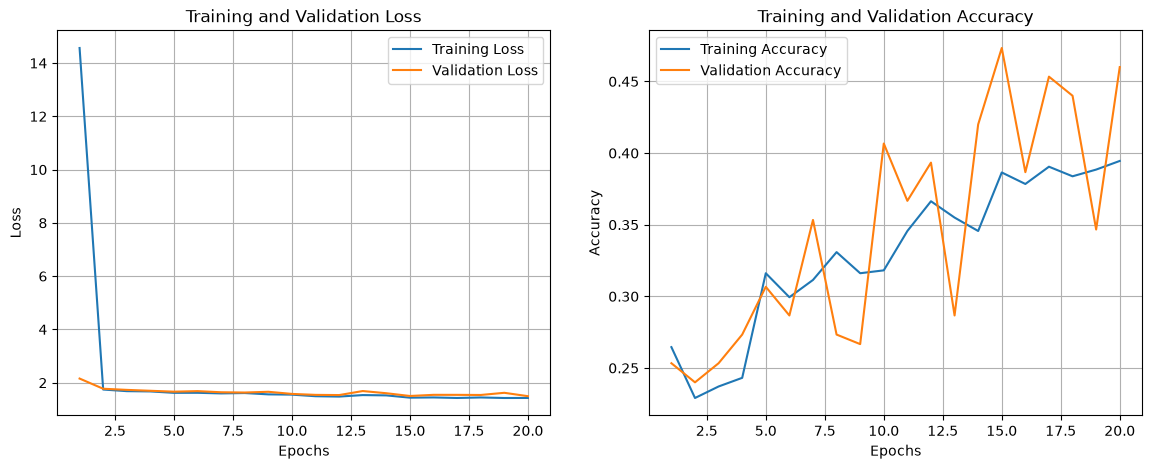

TEST REPORT
Overall Test Loss: 1.4442
Overall Test Accuracy: 0.4733

Per-Class Metrics (F1-Score):
              precision    recall  f1-score   support

       boots       0.42      0.48      0.44        21
  flip_flops       0.40      0.64      0.49        25
     loafers       0.38      0.37      0.38        27
     sandals       0.29      0.25      0.27        24
    sneakers       0.68      0.50      0.58        26
soccer_shoes       0.80      0.59      0.68        27

    accuracy                           0.47       150
   macro avg       0.50      0.47      0.47       150
weighted avg       0.50      0.47      0.48       150

CONFUSION MATRIX


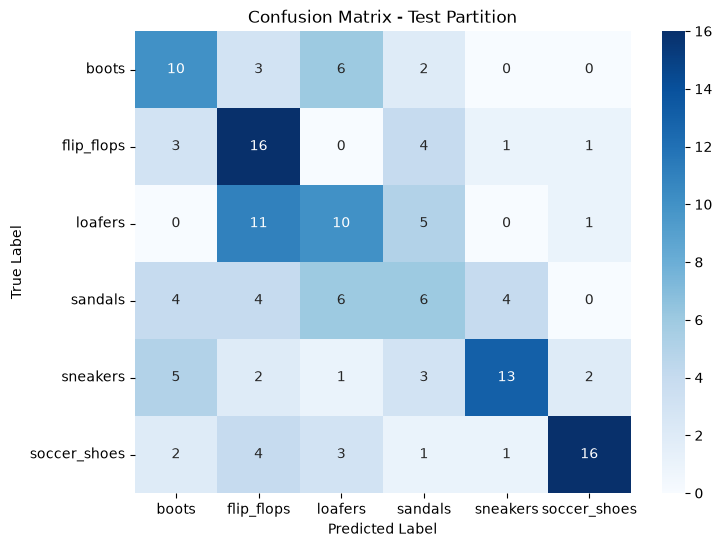

In [7]:
from sklearn.metrics import classification_report, confusion_matrix

epochs_range = range(1, EPOCHS + 1)
plt.figure(figsize=(14, 5))

# Loss Subplot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], label='Training Loss')
plt.plot(epochs_range, history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Accuracy Subplot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['train_acc'], label='Training Accuracy')
plt.plot(epochs_range, history['val_acc'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Test Report & Confusion Matrix
model.eval()
test_loss, correct, total = 0.0, 0, 0
all_preds = []
all_targets = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        test_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
        all_preds.extend(predicted.cpu().numpy())
        all_targets.extend(labels.cpu().numpy())

test_loss = test_loss / len(test_loader)
test_acc = correct / total

print("TEST REPORT")
print(f"Overall Test Loss: {test_loss:.4f}")
print(f"Overall Test Accuracy: {test_acc:.4f}\n")
print("Per-Class Metrics (F1-Score):")
print(classification_report(all_targets, all_preds, target_names=class_names))

print("CONFUSION MATRIX")
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Test Partition')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()